# IMU Gesture Recognition — Model Training

Loads the 6-axis IMU gesture CSVs from `data/raw_new/`, trains an MLP baseline and a 1D CNN, evaluates both, and exports the trained models + normalization files to `imu_live_demo/` for the live demo scripts.

Pipeline step: run this AFTER collecting data with `logger.py` and BEFORE running any of the live demo scripts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, precision_score, recall_score, f1_score,  roc_curve, auc
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
import joblib
import numpy as np


still_df = pd.read_csv("D:\RESUME PROJECTS/IMU Gesture remote/data/raw_new/still.csv")
left_df = pd.read_csv("D:\RESUME PROJECTS/IMU Gesture remote/data/raw_new/tilt_left.csv")
right_df = pd.read_csv("D:\RESUME PROJECTS/IMU Gesture remote/data/raw_new/tilt_right.csv")
up_df = pd.read_csv("D:\RESUME PROJECTS/IMU Gesture remote/data/raw_new/tilt_up.csv")
down_df = pd.read_csv("D:\RESUME PROJECTS/IMU Gesture remote/data/raw_new/tilt_down.csv")
shake_df = pd.read_csv("D:\RESUME PROJECTS/IMU Gesture remote/data/raw_new/shake.csv")

"""
still_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Intro to AI/IMU_AI/data/raw/still/still.csv")
left_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Intro to AI/IMU_AI/data/raw/left/left.csv")
right_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Intro to AI/IMU_AI/data/raw/right/right.csv")
up_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Intro to AI/IMU_AI/data/raw/up/up.csv")
down_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Intro to AI/IMU_AI/data/raw/down/down.csv")
shake_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Intro to AI/IMU_AI/data/raw/shake/shake.csv") """



<>:22: SyntaxWarning: invalid escape sequence '\R'
<>:23: SyntaxWarning: invalid escape sequence '\R'
<>:24: SyntaxWarning: invalid escape sequence '\R'
<>:25: SyntaxWarning: invalid escape sequence '\R'
<>:26: SyntaxWarning: invalid escape sequence '\R'
<>:27: SyntaxWarning: invalid escape sequence '\R'
<>:22: SyntaxWarning: invalid escape sequence '\R'
<>:23: SyntaxWarning: invalid escape sequence '\R'
<>:24: SyntaxWarning: invalid escape sequence '\R'
<>:25: SyntaxWarning: invalid escape sequence '\R'
<>:26: SyntaxWarning: invalid escape sequence '\R'
<>:27: SyntaxWarning: invalid escape sequence '\R'
C:\Users\wrayj\AppData\Local\Temp\ipykernel_24972\2763414748.py:22: SyntaxWarning: invalid escape sequence '\R'
  still_df = pd.read_csv("D:\RESUME PROJECTS/IMU Gesture remote/data/raw_new/still.csv")
C:\Users\wrayj\AppData\Local\Temp\ipykernel_24972\2763414748.py:23: SyntaxWarning: invalid escape sequence '\R'
  left_df = pd.read_csv("D:\RESUME PROJECTS/IMU Gesture remote/data/raw_new

'\nstill_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Intro to AI/IMU_AI/data/raw/still/still.csv")\nleft_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Intro to AI/IMU_AI/data/raw/left/left.csv")\nright_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Intro to AI/IMU_AI/data/raw/right/right.csv")\nup_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Intro to AI/IMU_AI/data/raw/up/up.csv")\ndown_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Intro to AI/IMU_AI/data/raw/down/down.csv")\nshake_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Intro to AI/IMU_AI/data/raw/shake/shake.csv") '

## Load and combine gesture CSVs

In [2]:
df = pd.concat([still_df, left_df, right_df, up_df, down_df, shake_df],
               ignore_index=True)

In [3]:
print(df.head())
print(df.shape)

   session_id gesture  trial_id  timestamp_ms    ax_g    ay_g    az_g  gx_dps  \
0           1   still         1             2  0.1060  0.1394  0.9853 -5.1119   
1           1   still         1            24  0.1029  0.1340  0.9936 -4.8142   
2           1   still         1            46  0.0694  0.1343  0.9968 -4.1425   
3           1   still         1            68  0.0789  0.1357  0.9719 -4.8982   
4           1   still         1            90  0.0582  0.1255  1.0029 -5.5623   

   gy_dps  gz_dps  
0  0.5619 -1.3988  
1  0.5771 -5.1469  
2 -0.3007 -4.7117  
3  2.3481 -2.8644  
4  5.5084 -2.4751  
(6120, 10)


In [4]:
label_map = {
    "left": "left",
    "tilt_left": "left",
    "right": "right",
    "tilt_right": "right",
    "up": "up",
    "tilt_up": "up",
    "down": "down",
    "tilt_down": "down",
    "shake": "shake",
    "still": "still"
}

df["gesture"] = df["gesture"].map(label_map)
df = df.dropna(subset=["gesture"]).copy()

In [5]:
print(df["gesture"].unique())
print(df["gesture"].value_counts())

['still' 'left' 'right' 'up' 'down' 'shake']
gesture
still    1020
left     1020
right    1020
down     1020
shake    1020
up        969
Name: count, dtype: int64


## Build fixed-length windows from trial data

In [6]:
df["trial_key"] = (
    df["session_id"].astype(str) + "_" +
    df["gesture"].astype(str) + "_" +
    df["trial_id"].astype(str)
)

In [7]:
feature_cols = ["ax_g", "ay_g", "az_g", "gx_dps", "gy_dps", "gz_dps"]

X = []
y = []

for trial_key, group in df.groupby("trial_key"):
    group = group.sort_values("timestamp_ms")
    sample = group[feature_cols].values.astype(np.float32)

    if len(sample) != 51:
        continue

    X.append(sample)
    y.append(group["gesture"].iloc[0])

X = np.stack(X)
y = np.array(y)

print("X shape:", X.shape)   # should be (num_samples, 51, 6)
print("y shape:", y.shape)

X shape: (119, 51, 6)
y shape: (119,)


In [8]:
print("# of samples:", len(X))
if len(X) > 0:
    print("First label:", y[0])
if len(X) > 3:
    print("4th label:", y[3])
if len(X) > 4:
    print("5th label:", y[4])
if len(X) > 20:
    print("21st label:", y[20])

# Safely print larger indices if they exist
if len(X) > 60:
    print("61st label:", y[60])
if len(X) > 119:
    print("120th label:", y[119])

if len(X) > 0:
    print("sample shape:", X[0].shape)

# of samples: 119
First label: down
4th label: down
5th label: down
21st label: left
61st label: shake
sample shape: (51, 6)


In [9]:
print(sorted(set(y)))
from collections import Counter
print(Counter(y))

[np.str_('down'), np.str_('left'), np.str_('right'), np.str_('shake'), np.str_('still'), np.str_('up')]
Counter({np.str_('down'): 20, np.str_('left'): 20, np.str_('right'): 20, np.str_('shake'): 20, np.str_('still'): 20, np.str_('up'): 19})


In [10]:
# Pad all sequences to the same length
X_padded = pad_sequences(X, dtype='float32', padding='post', maxlen=None)
y = np.array(y)

print("X shape:", X_padded.shape)  # Now (150, 47, 6)
print("y shape:", y.shape)

# Continue with your model training:
X = X_padded  # Replace X with padded version

X shape: (119, 51, 6)
y shape: (119,)


## Encode labels and split train/val/test

In [11]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Class names:", label_encoder.classes_)
print("Encoded labels:", y_encoded[:10])

Class names: ['down' 'left' 'right' 'shake' 'still' 'up']
Encoded labels: [0 0 0 0 0 0 0 0 0 0]


In [12]:
for label, encoded in zip(label_encoder.classes_, range(len(label_encoder.classes_))):
    print(label, "->", encoded)

down -> 0
left -> 1
right -> 2
shake -> 3
still -> 4
up -> 5


In [13]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)
print("y_test shape:", y_test.shape)

X_train shape: (83, 51, 6)
X_val shape: (18, 51, 6)
X_test shape: (18, 51, 6)
y_train shape: (83,)
y_val shape: (18,)
y_test shape: (18,)


## Normalize features (z-score from training set)

In [14]:
feature_mean = X_train.reshape(-1, 6).mean(axis=0)
feature_std = X_train.reshape(-1, 6).std(axis=0) + 1e-8

X_train = (X_train - feature_mean) / feature_std
X_val   = (X_val   - feature_mean) / feature_std
X_test  = (X_test  - feature_mean) / feature_std

np.save("feature_mean.npy", feature_mean)
np.save("feature_std.npy", feature_std)

print("feature_mean:", feature_mean)
print("feature_std:", feature_std)

feature_mean: [ 0.06792349  0.0364644   0.6216578  11.459305    1.3124188  -0.23477109]
feature_std: [ 0.62551147  0.3940084   0.49587372 63.9702     48.930237   38.749252  ]


## Train MLP baseline

In [15]:
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat   = X_val.reshape(X_val.shape[0], -1)
X_test_flat  = X_test.reshape(X_test.shape[0], -1)

print("X_train_flat shape:", X_train_flat.shape)
print("X_val_flat shape:", X_val_flat.shape)
print("X_test_flat shape:", X_test_flat.shape)

X_train_flat shape: (83, 306)
X_val_flat shape: (18, 306)
X_test_flat shape: (18, 306)


In [16]:
mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42
)
mlp.fit(X_train_flat, y_train)

,hidden_layer_sizes,"(128, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,300
,shuffle,True
,random_state,42


In [17]:
y_pred_mlp = mlp.predict(X_test_flat)

MLP Accuracy: 1.0

Classification Report:

              precision    recall  f1-score   support

        down       1.00      1.00      1.00         3
        left       1.00      1.00      1.00         3
       right       1.00      1.00      1.00         3
       shake       1.00      1.00      1.00         3
       still       1.00      1.00      1.00         3
          up       1.00      1.00      1.00         3

    accuracy                           1.00        18
   macro avg       1.00      1.00      1.00        18
weighted avg       1.00      1.00      1.00        18



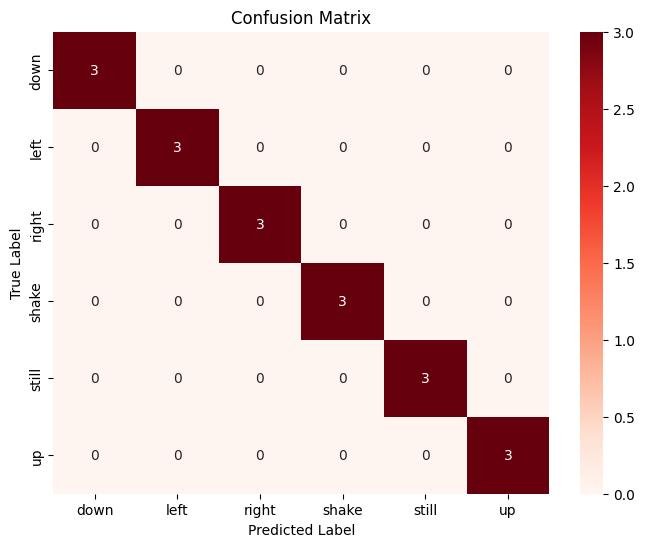

In [18]:
print("MLP Accuracy:", accuracy_score(y_test, y_pred_mlp))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_mlp, target_names=label_encoder.classes_))


cm = confusion_matrix(y_test, y_pred_mlp)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [19]:
# Save the trained MLP model
joblib.dump(mlp, "imu_gesture_mlp.pkl")

# Save the class labels in the same order used by the model
np.save("label_classes.npy", label_encoder.classes_)

print("Saved: imu_gesture_mlp.pkl")
print("Saved: label_classes.npy")

np.save("feature_mean.npy", feature_mean)
np.save("feature_std.npy", feature_std)

print("Saved: feature_mean.npy")
print("Saved: feature_std.npy")

Saved: imu_gesture_mlp.pkl
Saved: label_classes.npy
Saved: feature_mean.npy
Saved: feature_std.npy


## Train 1D CNN

In [20]:
num_classes = len(label_encoder.classes_)

y_train_cat = to_categorical(y_train, num_classes=num_classes)
y_val_cat   = to_categorical(y_val, num_classes=num_classes)
y_test_cat  = to_categorical(y_test, num_classes=num_classes)

print("y_train_cat shape:", y_train_cat.shape)
print("y_val_cat shape:", y_val_cat.shape)
print("y_test_cat shape:", y_test_cat.shape)

y_train_cat shape: (83, 6)
y_val_cat shape: (18, 6)
y_test_cat shape: (18, 6)


In [21]:
cnn_model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    Conv1D(filters=32, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Conv1D(filters=64, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

In [22]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [23]:
cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()


history = cnn_model.fit(
    X_train,
    y_train_cat,
    epochs=20,
    batch_size=8,
    validation_data=(X_val, y_val_cat),
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 49, 32)         │           608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 24, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 22, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 11, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 704)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        45,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,326 (204.40 KB)

 Trainable params: 52,326 (204.40 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.3855 - loss: 1.5336 - val_accuracy: 0.7778 - val_loss: 1.1038
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8193 - loss: 0.8598 - val_accuracy: 0.8333 - val_loss: 0.5393
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8795 - loss: 0.4403 - val_accuracy: 1.0000 - val_loss: 0.2461
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9277 - loss: 0.2477 - val_accuracy: 1.0000 - val_loss: 0.1169
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9639 - loss: 0.1356 - val_accuracy: 1.0000 - val_loss: 0.0615
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0694 - val_accuracy: 1.0000 - val_loss: 0.0321
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0604 - val_accuracy: 1.0000 - val_loss: 0.0222
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0239 - val_accuracy: 1.0000 - val_loss

In [24]:
test_loss, test_accuracy = cnn_model.evaluate(X_test, y_test_cat, verbose=0)

print("CNN Test Accuracy:", test_accuracy)

CNN Test Accuracy: 1.0


In [25]:
y_pred_probs = cnn_model.predict(X_test)
y_pred_cnn = np.argmax(y_pred_probs, axis=1)

print("First 10 CNN predictions:", y_pred_cnn[:10])
print("First 10 true labels:", y_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
First 10 CNN predictions: [5 1 3 2 0 0 3 4 2 5]
First 10 true labels: [5 1 3 2 0 0 3 4 2 5]


CNN Classification Report:

              precision    recall  f1-score   support

        down       1.00      1.00      1.00         3
        left       1.00      1.00      1.00         3
       right       1.00      1.00      1.00         3
       shake       1.00      1.00      1.00         3
       still       1.00      1.00      1.00         3
          up       1.00      1.00      1.00         3

    accuracy                           1.00        18
   macro avg       1.00      1.00      1.00        18
weighted avg       1.00      1.00      1.00        18



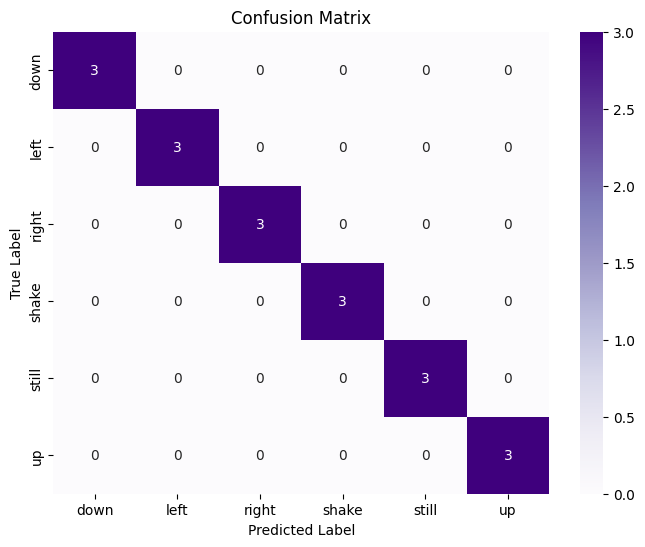

In [26]:
print("CNN Classification Report:\n")
print(classification_report(y_test, y_pred_cnn, target_names=label_encoder.classes_))


cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

The baseline MLP and the 1D CNN both achieved 100% classification accuracy on the test set. This indicates that the recorded gesture classes were highly separable in the collected dataset. The confusion matrices showed no misclassifications across the six gesture categories. While this is a strong result, it likely reflects the controlled recording setup and limited variability of the dataset. Additional experiments were therefore needed to better understand model behavior under more challenging conditions.

## Reduced-data experiment (robustness check)

In [27]:
X_train_small, _, y_train_small, _ = train_test_split(
    X_train, y_train,
    train_size=0.5,
    random_state=42,
    stratify=y_train
)

print("Original X_train shape:", X_train.shape)
print("Reduced X_train_small shape:", X_train_small.shape)
print("Original y_train shape:", y_train.shape)
print("Reduced y_train_small shape:", y_train_small.shape)

Original X_train shape: (83, 51, 6)
Reduced X_train_small shape: (41, 51, 6)
Original y_train shape: (83,)
Reduced y_train_small shape: (41,)


In [28]:
X_train_small_flat = X_train_small.reshape(X_train_small.shape[0], -1)

print("X_train_small_flat shape:", X_train_small_flat.shape)
print("X_test_flat shape:", X_test_flat.shape)

X_train_small_flat shape: (41, 306)
X_test_flat shape: (18, 306)


In [29]:
mlp_small = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='relu',
    solver='adam',
    max_iter=300,
    random_state=42
)

mlp_small.fit(X_train_small_flat, y_train_small)

,hidden_layer_sizes,"(128, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,300
,shuffle,True
,random_state,42


Reduced-Data MLP Accuracy: 1.0

Reduced-Data MLP Classification Report:

              precision    recall  f1-score   support

        down       1.00      1.00      1.00         3
        left       1.00      1.00      1.00         3
       right       1.00      1.00      1.00         3
       shake       1.00      1.00      1.00         3
       still       1.00      1.00      1.00         3
          up       1.00      1.00      1.00         3

    accuracy                           1.00        18
   macro avg       1.00      1.00      1.00        18
weighted avg       1.00      1.00      1.00        18



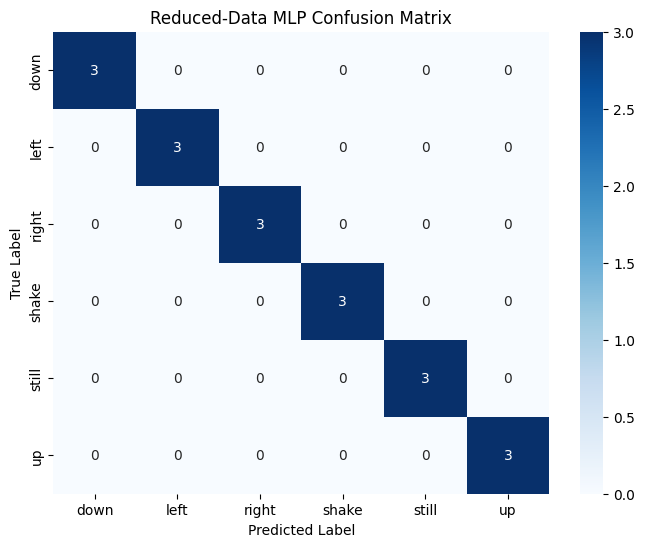

In [30]:
y_pred_mlp_small = mlp_small.predict(X_test_flat)

print("Reduced-Data MLP Accuracy:", accuracy_score(y_test, y_pred_mlp_small))
print("\nReduced-Data MLP Classification Report:\n")
print(classification_report(y_test, y_pred_mlp_small, target_names=label_encoder.classes_))
cm = confusion_matrix(y_test, y_pred_mlp_small)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Reduced-Data MLP Confusion Matrix')
plt.show()

In [31]:
num_classes = len(label_encoder.classes_)

y_train_small_cat = to_categorical(y_train_small, num_classes=num_classes)

print("y_train_small_cat shape:", y_train_small_cat.shape)
print("y_test_cat shape:", y_test_cat.shape)

y_train_small_cat shape: (41, 6)
y_test_cat shape: (18, 6)


In [32]:
cnn_small = Sequential([
    Input(shape=(X_train_small.shape[1], X_train_small.shape[2])),
    Conv1D(filters=32, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Conv1D(filters=64, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

cnn_small.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_small = cnn_small.fit(
    X_train_small,
    y_train_small_cat,
    epochs=20,
    batch_size=8,
    validation_data=(X_test, y_test_cat),
    verbose=1
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.2927 - loss: 1.7478 - val_accuracy: 0.6111 - val_loss: 1.3319
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6829 - loss: 1.1858 - val_accuracy: 0.7222 - val_loss: 0.9811
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8780 - loss: 0.8405 - val_accuracy: 0.8889 - val_loss: 0.6874
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8537 - loss: 0.6059 - val_accuracy: 0.9444 - val_loss: 0.4660
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9512 - loss: 0.3622 - val_accuracy: 1.0000 - val_loss: 0.2895
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9512 - loss: 0.2532 - val_accuracy: 0.9444 - val_loss: 0.1773
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.1256 - val_accuracy: 1.0000 - val_loss: 0.1050
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 1.0000 - loss: 0.0802 - val_accuracy: 1.0000 - val_loss: 0.1007
Epoch 9

In [35]:
test_loss_small, test_accuracy_small = cnn_small.evaluate(X_test, y_test_cat, verbose=0)

print("Reduced-Data CNN Test Accuracy:", test_accuracy_small)

Reduced-Data CNN Test Accuracy: 1.0


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step

Reduced-Data CNN Classification Report:

              precision    recall  f1-score   support

        down       1.00      1.00      1.00         3
        left       1.00      1.00      1.00         3
       right       1.00      1.00      1.00         3
       shake       1.00      1.00      1.00         3
       still       1.00      1.00      1.00         3
          up       1.00      1.00      1.00         3

    accuracy                           1.00        18
   macro avg       1.00      1.00      1.00        18
weighted avg       1.00      1.00      1.00        18



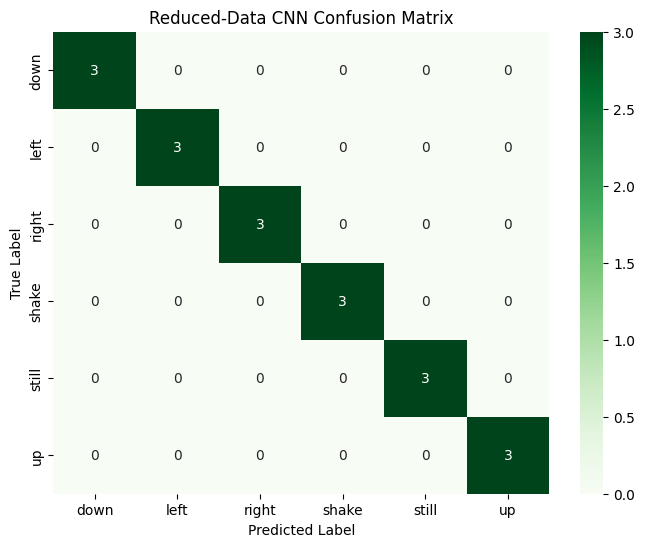

In [36]:
y_pred_probs_small = cnn_small.predict(X_test)
y_pred_cnn_small = np.argmax(y_pred_probs_small, axis=1)

print("\nReduced-Data CNN Classification Report:\n")
print(classification_report(y_test, y_pred_cnn_small, target_names=label_encoder.classes_))

cm = confusion_matrix(y_test, y_pred_cnn_small)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Reduced-Data CNN Confusion Matrix')
plt.show()

In the full-data setting, both the MLP and 1D CNN achieved 100% accuracy on the test set. However, when the training set was reduced to 50% of its original size, the MLP accuracy dropped to 91.67%, while the CNN maintained 100% accuracy. The reduced-data MLP misclassified one down gesture as right and one shake gesture as up. This suggests that the CNN was more robust to limited training data, likely because it preserved the temporal structure of the IMU signals rather than flattening them into a single feature vector.

## Export trained models and normalization files

In [ ]:
cnn_model.save("imu_gesture_cnn.keras")

np.save("label_classes.npy", label_encoder.classes_)